# Task 7: Demand Forecasting

Run `python src/forecast.py` first. It forecasts weekly new roles per company over a shared 8-week horizon from `weekly_postings.csv` (Task 5), with the same candidate models and the same backtest for all four. Target: `new_roles_adjusted` (survivorship-adjusted unique new roles). With 26 weekly points, no seasonality (under a year of data) and no deep learning, the candidates are simple: naive, 4-week moving average, drift, simple exponential smoothing, damped Holt, ARIMA (small grid by AIC) and Prophet with seasonality off.

Treat every forecast as uncertain: the adjusted series is itself an estimate (correction capped at 3x), and its growth moved about 30 points between two snapshots.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
P = "../data/processed/"
weekly = pd.read_csv(P + "weekly_postings.csv", parse_dates=["week_start"]).dropna(subset=["new_roles_unique"])
fc = pd.read_csv(P + "forecasts.csv", parse_dates=["week_start"])
bt = pd.read_csv(P + "backtest_metrics.csv")
sens = pd.read_csv(P + "forecast_sensitivity.csv", parse_dates=["week_start"])
cc = pd.read_csv(P + "forecast_crosscheck.csv")

ORDER = ["OpenAI", "Anthropic", "Databricks", "NVIDIA"]
COLOR = {"OpenAI": "#1c5cab", "Anthropic": "#d9772b", "Databricks": "#b5342c", "NVIDIA": "#3f8f2f"}
GREY = "#8b949e"
MODELS = ["naive", "ma4", "drift", "ses", "holt_damped", "arima", "prophet"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
chosen = bt[(bt.target == "adjusted") & bt.chosen].set_index("company_name")
chosen[["model", "mae", "mase", "beats_naive", "coverage80", "coverage95", "n_origins"]].reindex(ORDER)

,model,mae,mase,beats_naive,coverage80,coverage95,n_origins
company_name,,,,,,,
OpenAI,ma4,17.19,0.741,True,0.838,0.985,12
Anthropic,naive,20.25,1.000,False,1.000,1.000,12
Databricks,holt_damped,11.82,0.845,True,0.824,0.985,12
NVIDIA,prophet,48.72,0.804,True,0.400,0.633,11


## 1. Forecast fan charts

History (adjusted, solid; unique roles, faint), the chosen model's 8-week forecast, and 80% and 95% intervals clipped at 0. The dotted line is the last complete week. NVIDIA's data ends a week earlier than the others, so its forecast starts a week earlier.

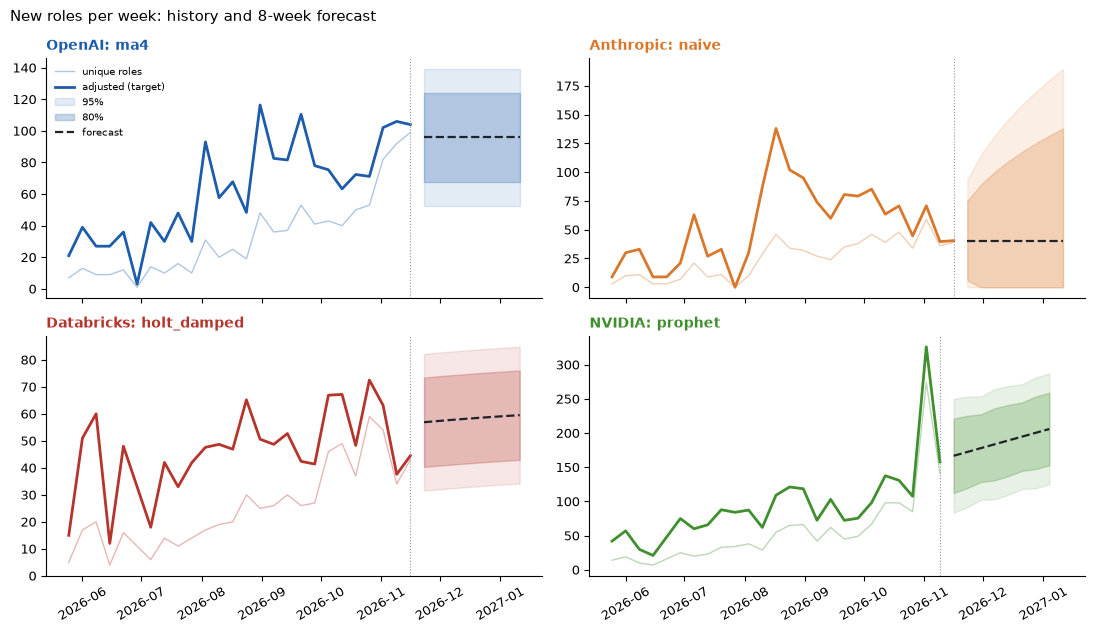

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for ax, c in zip(axes.flat, ORDER):
    h = weekly[weekly.company_name == c]; f = fc[fc.company_name == c]
    ax.plot(h.week_start, h.new_roles_unique, color=COLOR[c], lw=1, alpha=.35, label="unique roles")
    ax.plot(h.week_start, h.new_roles_adjusted, color=COLOR[c], lw=2, label="adjusted (target)")
    ax.fill_between(f.week_start, f.lo95, f.hi95, color=COLOR[c], alpha=.12, label="95%")
    ax.fill_between(f.week_start, f.lo80, f.hi80, color=COLOR[c], alpha=.25, label="80%")
    ax.plot(f.week_start, f.forecast, color="#1f2328", lw=1.6, ls="--", label="forecast")
    ax.axvline(h.week_start.max(), color=GREY, lw=.8, ls=":")
    ax.set_title(f"{c}: {f.model.iloc[0]}", loc="left", fontsize=10, color=COLOR[c], fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("New roles per week: history and 8-week forecast", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**Reading it:** OpenAI's moving average gives a flat forecast near 96 roles a week with a wide band; the model has no view on direction. Anthropic's naive forecast is 40.5 a week and the 95% band spans 0 to 190 by week 8: the series is too jumpy for a tight statement. Databricks drifts gently from 57 to 60. NVIDIA's Prophet forecast rises from 167 to 206, a trend that leans on the large week of 2 Nov.

## 2. Backtest: which model wins

Rolling origin, expanding window, first origin after 14 weeks, up to 8 weeks ahead. MASE is the model's MAE divided by naive's MAE on the same origins and steps, so naive is 1.0. Below 1.0 beats naive; a model needs under 0.95 to be chosen over naive. Stars mark the chosen model.

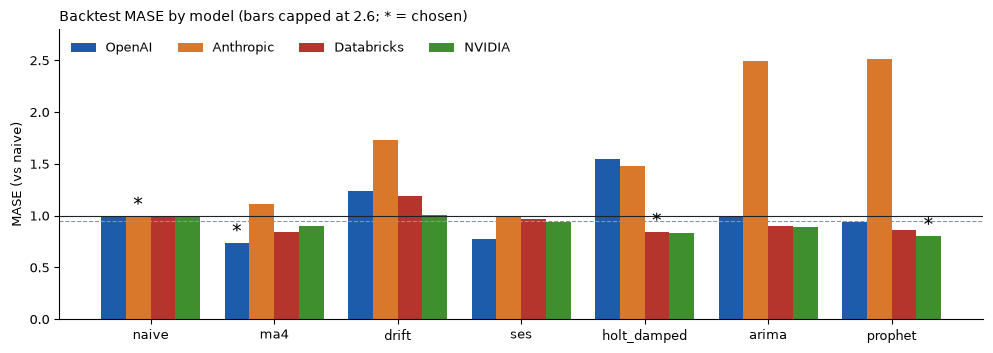

company_name,OpenAI,Anthropic,Databricks,NVIDIA
model,,,,
naive,1.00,1.00,1.00,1.00
ma4,0.74,1.11,0.85,0.90
drift,1.24,1.73,1.19,1.01
ses,0.77,1.00,0.97,0.94
holt_damped,1.55,1.48,0.84,0.84
arima,0.98,2.49,0.90,0.89
prophet,0.94,2.52,0.87,0.80


In [3]:
m = bt[bt.target == "adjusted"].pivot(index="model", columns="company_name", values="mase").reindex(MODELS)[ORDER]
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(MODELS)); w = .2
for k, c in enumerate(ORDER):
    vals = m[c].clip(upper=2.6)
    ax.bar(x + (k - 1.5) * w, vals, w, color=COLOR[c], label=c)
    j = MODELS.index(chosen.loc[c, "model"]); ax.text(j + (k - 1.5) * w, vals.iloc[j] + .05, "*", ha="center", fontsize=14)
ax.axhline(1, color="#1f2328", lw=.8); ax.axhline(.95, color=GREY, lw=.8, ls="--")
ax.set_xticks(x, MODELS); ax.set_ylabel("MASE (vs naive)"); ax.set_ylim(0, 2.8); ax.legend(frameon=False, ncol=4)
ax.set_title("Backtest MASE by model (bars capped at 2.6; * = chosen)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
m.round(2)

**Reading it:** the 4-week moving average wins for OpenAI (0.74). For Anthropic nothing beats naive: SES scores 1.00 (no better than naive), the moving average 1.11, and ARIMA and Prophet are far worse (about 2.5), so naive is used. Damped Holt wins narrowly for Databricks (0.845 against the moving average's 0.846, a tie in practice). Prophet wins for NVIDIA (0.80, damped Holt 0.84). The gaps between the best few models are within what 11 to 12 origins can resolve.

Do the same models win on the unadjusted series? Backtest on `new_roles_unique`:

In [4]:
mu = bt[bt.target == "unique"].pivot(index="model", columns="company_name", values="mase").reindex(MODELS)[ORDER]
print("Winner on the unique-roles series:", bt[(bt.target == "unique") & bt.chosen].set_index("company_name").model.reindex(ORDER).to_dict())
mu.round(2)

Winner on the unique-roles series: {'OpenAI': 'prophet', 'Anthropic': 'prophet', 'Databricks': 'arima', 'NVIDIA': 'prophet'}


company_name,OpenAI,Anthropic,Databricks,NVIDIA
model,,,,
naive,1.00,1.00,1.00,1.00
ma4,1.13,0.92,1.06,1.00
drift,0.84,0.96,0.85,0.91
ses,1.06,0.98,1.03,0.99
holt_damped,0.86,0.92,0.85,0.91
arima,0.79,0.96,0.79,0.83
prophet,0.78,0.78,0.82,0.79


**Reading it:** on the unadjusted series Prophet or ARIMA beat naive for every company, with a best MASE of 0.78 to 0.79 each. On the adjusted series the gain from trend models is weaker and uneven: none for Anthropic, small for OpenAI (Prophet 0.94, ARIMA 0.98, while the moving average gets 0.74), larger for Databricks and NVIDIA. That is consistent with the unadjusted series carrying the survivorship ramp, which trend models extrapolate and the adjustment largely removes. It is a reason to forecast the adjusted series, not a sign that trend models are better.

## 3. Interval calibration

Share of backtest actuals that fell inside the chosen model's intervals (nominal 80% and 95%).

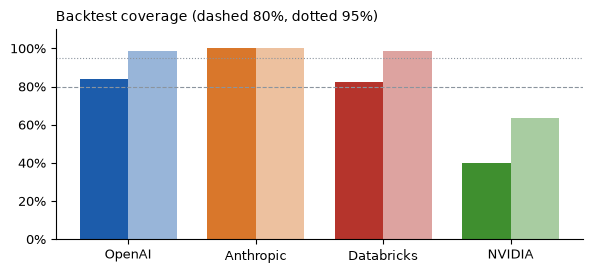

,model,coverage80,coverage95
company_name,,,
OpenAI,ma4,0.838,0.985
Anthropic,naive,1.000,1.000
Databricks,holt_damped,0.824,0.985
NVIDIA,prophet,0.400,0.633


In [5]:
cal = chosen.loc[ORDER, ["model", "coverage80", "coverage95"]]
fig, ax = plt.subplots(figsize=(6, 2.8)); x = np.arange(4); w = .38
ax.bar(x - w/2, cal.coverage80, w, color=[COLOR[c] for c in ORDER], label="80% interval")
ax.bar(x + w/2, cal.coverage95, w, color=[COLOR[c] for c in ORDER], alpha=.45, label="95% interval")
ax.axhline(.8, color=GREY, ls="--", lw=.8); ax.axhline(.95, color=GREY, ls=":", lw=.8)
ax.set_xticks(x, ORDER); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0, 1.1)
ax.set_title("Backtest coverage (dashed 80%, dotted 95%)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
cal

**Reading it:** OpenAI and Databricks intervals are close to nominal at 80% and slightly wide at 95%. Anthropic's are far too wide (100%). NVIDIA's Prophet intervals are too narrow: only 40% of actuals fell inside the 80% band and 63% inside the 95% band, so read them as optimistic.

## 4. Sensitivity

Two checks on the chosen model: the unique-roles target (no survivorship adjustment) and a refit on August onwards, because earlier weeks are floors where the correction hits its 3x cap.

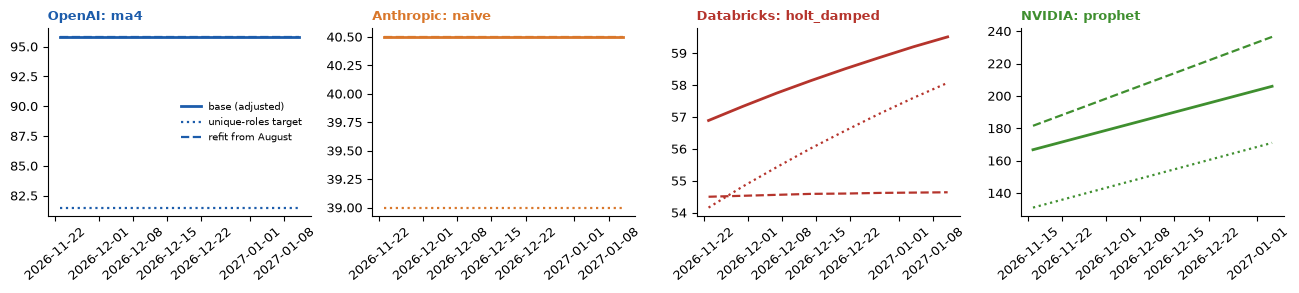

weeks_fitted               mean_forecast                \
scenario      from_august unique_target   from_august unique_target   
company_name                                                          
OpenAI                 16            26          95.8          81.5   
Anthropic              16            26          40.5          39.0   
Databricks             16            26          54.6          56.2   
NVIDIA                 15            25         209.0         151.0   

               mean_base               mean_diff_pct                
scenario     from_august unique_target   from_august unique_target  
company_name                                                        
OpenAI              95.8          95.8           0.0         -14.9  
Anthropic           40.5          40.5           0.0          -3.7  
Databricks          58.3          58.3          -6.3          -3.5  
NVIDIA             186.4         186.4          12.0         -19.1

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharex=False)
STYLE = {"base": ("-", 2, "base (adjusted)"), "unique_target": (":", 1.6, "unique-roles target"), "from_august": ("--", 1.6, "refit from August")}
for ax, c in zip(axes, ORDER):
    for sc, (ls, lw, lab) in STYLE.items():
        d = sens[(sens.company_name == c) & (sens.scenario == sc)]
        ax.plot(d.week_start, d.forecast, color=COLOR[c], ls=ls, lw=lw, label=lab)
    ax.set_title(f"{c}: {sens[sens.company_name == c].model.iloc[0]}", loc="left", fontsize=9, color=COLOR[c], fontweight="bold")
    ax.tick_params(axis="x", rotation=40)
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()
s = sens[sens.scenario != "base"].groupby(["company_name", "scenario"]).agg(
    weeks_fitted=("n_weeks_fitted", "first"), mean_forecast=("forecast", "mean"), mean_base=("base_forecast", "mean"),
    mean_diff_pct=("diff_pct", "mean")).round(1)
s.unstack("scenario").reindex(ORDER)

**Reading it:** refitting from August changes nothing for OpenAI and Anthropic, because the moving average and naive only use the last few weeks. It lowers Databricks by about 6% and raises NVIDIA by about 12%, with NVIDIA's trend steeper. The unique-roles target gives lower levels (15% lower for OpenAI, 19% for NVIDIA, about 4% for Anthropic and Databricks), which mostly reflects the survival adjustment itself, not a different view of the trend.

## 5. Cross-check against snapshot inflow

The forecast level for the next 2 weeks against the unbiased snapshot `opened_per_week`. NVIDIA's flows are provisional (one interval).

In [7]:
cc.set_index("company_name").reindex(ORDER)

,model,forecast_next2_mean,snapshot_opened_per_week,ratio,flows_provisional
company_name,,,,,
OpenAI,ma4,95.8,82.5,1.16,False
Anthropic,naive,40.5,44.6,0.91,False
Databricks,holt_damped,57.1,50.1,1.14,False
NVIDIA,prophet,169.6,145.8,1.16,True


**Reading it:** the forecasts sit within 16% of the snapshot inflow for every company (ratios 0.91 to 1.16), tighter than the Task 5 comparison of the latest two weeks with the same flows (0.82 to 1.27 for the three companies with full flows), as expected from a smoothed forecast. NVIDIA's 1.16 is provisional.